# <center>VAI Academy</center>
# <center>Projeto Final - Segmentação de Clientes</center>
___

## 1. Leitura das Bases

Nesta etapa, os principais insumos para a segmentação serão carregados

In [ ]:
# Import das libs utilizadas
import os
import pandas as pd
import numpy as np
from datetime import timedelta
import matplotlib.pyplot as plt
import seaborn as sns
from plotly.subplots import make_subplots
import plotly.graph_objects as go
import plotly.express as px
import plotly.io as pio
import matplotlib.pyplot as plt
import seaborn as sns
import pickle
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import AgglomerativeClustering
from sklearn.preprocessing import StandardScaler
import datetime

In [ ]:
cliente = pd.read_csv('cliente.csv',sep=';')
produtos = pd.read_csv('produto.csv',sep=',',dtype={'ID_PRODUTO': str})
venda = pd.read_csv('venda.csv',sep=',',dtype={'ID_CLIENTE': str,
                                               'ID_VENDA': str,
                                               'ID_PRODUTO': str,
                                               'FILIAL': str,'QUANTIDADE': str},decimal = '.')

## 2. Tratamento das Bases

Bases iniciais serão tratadas e consolidadas na base que será utilizada na segmentação

In [ ]:
# Ajustes na base de Venda
venda['DATA_VENDA'] = pd.to_datetime(venda['DATA_VENDA'], format='%Y/%m/%d', errors='coerce')
venda['QUANTIDADE'] = pd.to_numeric(venda['QUANTIDADE'].str.replace(',', ''))
venda['anomes'] = venda['DATA_VENDA'].apply(lambda x: datetime.date(x.year, x.month, 1))

venda = pd.merge(venda,produtos,how='left',on=['ID_PRODUTO'])

### 2.1 Consolidação da Base Transacional


In [ ]:
# Agrupando por Dia
venda_dia         = venda.groupby(['DATA_VENDA','anomes','ID_CLIENTE']).agg({'QUANTIDADE':['sum','count']}).reset_index()
venda_dia.columns = venda_dia.columns.droplevel(0)
venda_dia.columns = ['DATA_VENDA','anomes','ID_CLIENTE','quantidade','n_prod']

In [ ]:
# Agrupando por Mes
venda_mes = venda_dia.groupby(['anomes','ID_CLIENTE']).agg({'quantidade':['sum','count'],'n_prod':['mean']}).reset_index()
venda_mes.columns = venda_mes.columns.droplevel(0)
venda_mes.columns = ['anomes','ID_CLIENTE','quantidade','freq_int_mes','n_prod']

In [ ]:
# Agrupando por Cliente
venda_cliente = venda_mes.groupby(['ID_CLIENTE']).agg({'anomes':['max','min'],
                                                       'quantidade':['sum'],
                                                       'n_prod':['mean'],
                                                       'freq_int_mes':['sum','mean','count']}).reset_index()

venda_cliente.columns = venda_cliente.columns.droplevel(0)
venda_cliente.columns = ['ID_CLIENTE','ultima_compra','primeira_compra','qntd','n_prod','n_compras','freq_mes','n_meses']

In [ ]:
# Calculo de variáveis
venda_cliente['data_atual'] = datetime.date(2021,10, 1)

venda_cliente['recencia']      = venda_cliente.apply(lambda x: (x['data_atual'].year    - x['ultima_compra'].year) * 12   + (x['data_atual'].month    - x['ultima_compra'].month ),axis=1)
venda_cliente['tempo_relacao'] = venda_cliente.apply(lambda x: (x['ultima_compra'].year - x['primeira_compra'].year) * 12 + (x['ultima_compra'].month - x['primeira_compra'].month ),axis=1)
venda_cliente['idade_empresa'] = venda_cliente.apply(lambda x: (x['data_atual'].year    - x['primeira_compra'].year) * 12 + (x['data_atual'].month    - x['primeira_compra'].month ),axis=1)

### 2.2 Calculo do share por canal

In [ ]:
# Consolidação por Loja
venda_loja = venda.groupby(['DATA_VENDA','anomes','ID_CLIENTE','CATEGORIA_VENDA']).agg({'QUANTIDADE':['sum']}).reset_index()
venda_loja.columns = venda_loja.columns.droplevel(0)
venda_loja.columns = ['DATA_VENDA','anomes','ID_CLIENTE','CATEGORIA_VENDA','quantidade']

venda_loja = venda_loja.groupby(['anomes','ID_CLIENTE','CATEGORIA_VENDA']).agg({'quantidade':['sum','count']}).reset_index()
venda_loja.columns = venda_loja.columns.droplevel(0)
venda_loja.columns = ['anomes','ID_CLIENTE','CATEGORIA_VENDA','quantidade','n_compras']

venda_loja = venda_loja.groupby(['ID_CLIENTE','CATEGORIA_VENDA']).sum().reset_index()

In [ ]:
# Tratamento da Base consolidada
venda_loja['clinica_ncomp'] = 0
venda_loja.loc[venda_loja['CATEGORIA_VENDA']=='Clínica             ','clinica_ncomp'] = venda_loja['n_compras']

# Estetica
venda_loja['estetica_ncomp'] = 0
venda_loja.loc[venda_loja['CATEGORIA_VENDA']=='Estética            ','estetica_ncomp'] = venda_loja['n_compras']

# Loja
venda_loja['loja_ncomp'] = 0
venda_loja.loc[venda_loja['CATEGORIA_VENDA']=='Loja                ','loja_ncomp'] = venda_loja['n_compras']

# Digital
venda_loja['dig_ncomp'] = 0
venda_loja.loc[venda_loja['CATEGORIA_VENDA']=='Digital             ','dig_ncomp'] = venda_loja['n_compras']

# e-commerce
venda_loja['ecomm_ncomp'] = 0
venda_loja.loc[venda_loja['CATEGORIA_VENDA']=='E-COMMERCE          ','ecomm_ncomp'] = venda_loja['n_compras']

# Consolidacao do Calculo
venda_loja = venda_loja.groupby(['ID_CLIENTE']).sum().reset_index()
venda_loja = venda_loja.drop(['quantidade'],axis=1)

In [ ]:
# Calculo do Share
venda_loja['clinica_ncomp']  = venda_loja['clinica_ncomp']/venda_loja['n_compras']
venda_loja['estetica_ncomp'] = venda_loja['estetica_ncomp']/venda_loja['n_compras']
venda_loja['loja_ncomp']     = venda_loja['loja_ncomp']/venda_loja['n_compras']
venda_loja['dig_ncomp']      = venda_loja['dig_ncomp']/venda_loja['n_compras']
venda_loja['ecomm_ncomp']    = venda_loja['ecomm_ncomp']/venda_loja['n_compras']
venda_loja = venda_loja.drop(['n_compras'],axis=1)

### 2.3 Unificação da Base e ajustes finais

Descrição das variáveis construidas

*   **ultima_compra**
*   **primeira_compra**
*   **qntd:** Quantidade total de itens comprados
*   **n_prod:** Média de produtos adquiridos em uma compra
*   **n_compras:** número de compras total do cliente (um clientes so pode comprar 1 vez por dia)
*   **freq_mes:** Média de compras por mês
*   **n_meses:** número de meses em que comprou
*   **recencia**
*   **tempo_relacao:** meses entre a primeira e a ultima compra
*   **idade_empresa:** tempo desde a primeira compra
*   **clinica_ncomp:** percentual das compras feitas em clinicas
*   **estetica_ncomp:** percentual das compras feitas em estetica
*   **loja_ncomp:** percentual das compras feitas em loja
*   **dig_ncomp:** percentual das compras feitas em mrkt place
*   **ecomm_ncomp:** percentual das compras feitas em ecommerce
*   **qntd_compra:** Média da quantidade adquirida por compra

In [ ]:
# Unificação
base_final = pd.merge(venda_cliente,venda_loja,how='left',on=['ID_CLIENTE'])

In [ ]:
# Ajuste dos Campos
base_final['qntd_compra'] = base_final['qntd']/base_final['n_compras']
base_final = base_final.drop(['data_atual'],axis=1)

In [ ]:
base_final.head()

,ID_CLIENTE,ultima_compra,primeira_compra,qntd,n_prod,n_compras,freq_mes,n_meses,recencia,tempo_relacao,idade_empresa,clinica_ncomp,estetica_ncomp,loja_ncomp,dig_ncomp,ecomm_ncomp,qntd_compra
0,1000,2021-10-01,2020-01-01,4342.9,3.782407,40,2.222222,18,0,21,21,0.2,0.220000,0.580000,0.0,0.0,108.5725
1,100000,2021-09-01,2021-09-01,2.0,1.000000,1,1.000000,1,1,0,1,0.0,0.000000,0.000000,1.0,0.0,2.0000
2,100001,2021-10-01,2021-09-01,104.8,1.500000,2,1.000000,2,0,1,1,0.0,0.666667,0.333333,0.0,0.0,52.4000
3,100002,2021-09-01,2021-09-01,7.0,7.000000,1,1.000000,1,1,0,1,0.0,0.000000,1.000000,0.0,0.0,7.0000
4,100003,2021-10-01,2021-09-01,511.8,3.250000,8,4.000000,2,0,1,1,0.0,0.555556,0.444444,0.0,0.0,63.9750


## 3. Análise das Variáveis

Nesta etapa, as variaveis criadas serão analisadas

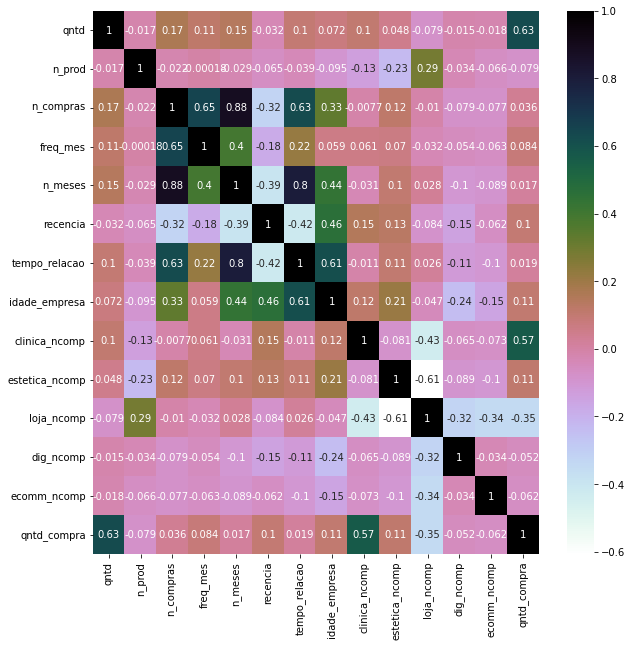

In [ ]:
# Avaliação da Correlação entre as variáveis
plt.figure(figsize=(10,10))
sns.heatmap(base_final[['qntd', 'n_prod','n_compras', 'freq_mes', 'n_meses', 'recencia',
       'tempo_relacao', 'idade_empresa', 'clinica_ncomp','estetica_ncomp',
       'loja_ncomp','dig_ncomp', 'ecomm_ncomp','qntd_compra']].corr(),annot=True,cmap='cubehelix_r')

plt.show()

In [ ]:
#var_analisada = 'qntd'
#var_analisada = 'n_prod'
#var_analisada = 'n_compras'
#var_analisada = 'freq_mes'
#var_analisada = 'n_meses'
var_analisada = 'recencia'
#var_analisada = 'tempo_relacao'
#var_analisada = 'idade_empresa'
#var_analisada = 'clinica_ncomp'
#var_analisada = 'estetica_ncomp'
#var_analisada = 'loja_ncomp'
#var_analisada = 'dig_ncomp'
#var_analisada = 'ecomm_ncomp'
#var_analisada = 'qntd_compra'

fig = px.box(base_final, x=var_analisada)
fig.update_traces(orientation='h')
fig.update_layout(
    xaxis={'title': var_analisada},
    yaxis={'title': var_analisada, 'showline': False, 'ticks': ''}
)
fig.show()

## 4. Clusterização

Etapa em que será realizada a clusterização

### 4.1 Seleção das Variáveis

In [ ]:
# Base de clientes simplificada [Variáveis utilizadas na clusterização, experimente clusterizar com diferentes variáveis]
clientes = base_final[['ID_CLIENTE','n_prod','qntd_compra','freq_mes', 'n_meses', 'recencia','loja_ncomp']]

### 4.2 Normalização das Variáveis

In [ ]:
# Base utilizada para clusterização

df_cluster = clientes.drop(['ID_CLIENTE'],axis=1)

# Normalização das variáveis
std_data = StandardScaler().fit_transform(df_cluster)
df_cluster = pd.DataFrame(data=std_data, columns=df_cluster.columns, index=df_cluster.index)

df_cluster.describe()

,n_prod,qntd_compra,freq_mes,n_meses,recencia,loja_ncomp
count,8.953500e+04,8.953500e+04,8.953500e+04,8.953500e+04,8.953500e+04,8.953500e+04
mean,4.508058e-16,1.027037e-15,-5.626742e-16,7.613733e-14,-1.421572e-14,3.073644e-16
std,1.000006e+00,1.000006e+00,1.000006e+00,1.000006e+00,1.000006e+00,1.000006e+00
min,-7.264561e-01,-3.012111e-01,-5.153730e-01,-7.168529e-01,-9.298197e-01,-1.798485e+00
25%,-7.264561e-01,-2.835752e-01,-5.153730e-01,-7.168529e-01,-7.312844e-01,-7.129298e-01
50%,-2.452758e-01,-2.707130e-01,-5.153730e-01,-4.121187e-01,-3.342138e-01,7.344764e-01
75%,2.760028e-01,-4.108010e-02,1.640278e-01,1.973497e-01,6.584626e-01,7.344764e-01
max,2.513698e+01,1.592018e+02,3.413407e+01,5.682566e+00,3.239422e+00,7.344764e-01


### 4.3 Definição do número de clusters

In [ ]:
# Cálculo das iterações do k-means (Cotovelo)

wcss = {}
for k in range(1, 26):
  print(k)
  kmeans = KMeans(n_clusters=k, init='k-means++', max_iter=200, random_state=3)
  kmeans.fit(df_cluster)
  wcss[k] = kmeans.inertia_

1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25


In [ ]:
fig = make_subplots(
    rows=1,
    cols=1,
    subplot_titles=['Método do Cotovelo'],
    shared_xaxes=True,
    shared_yaxes=False)


fig.add_trace(
    go.Scatter(
        x=list(wcss.keys()),
        y=list(wcss.values()),
        mode='lines+markers',
        textposition='top center',
        showlegend=False),
    row=1,
    col=1)

fig.update_xaxes(visible=True, title='No. of clusters',row=1, col=1)
fig.update_yaxes(visible=True, title='Cluster Inertia',row=1, col=1)

fig.update_layout(
  title='Definição do Nº Ideal de Clusters',
  showlegend=False,
  xaxis_showticklabels=True,
  height=400,
  width=800,
  xaxis = dict(
    tickmode = 'linear',
    tick0 = 0,
    dtick = 1))

fig.show()

### 4.4 Clusterização não Hierárquica (K-Means)

In [ ]:
# Definição do DF a ser Clusterizado
df_cluster_km = df_cluster.copy()

# Clusterização
clus = KMeans(n_clusters=5, init='k-means++', max_iter=300,random_state=3)
clus.fit(df_cluster_km)

# Ajustando as colunas
df_cluster_km.loc[:, 'CLUSTER'] = clus.labels_
df_cluster_km.head()

,n_prod,qntd_compra,freq_mes,n_meses,recencia,loja_ncomp,CLUSTER
0,0.947093,0.672688,1.975763,4.463629,-0.929820,-0.329367,4
1,-0.726456,-0.283271,-0.515373,-0.716853,-0.731284,-1.798485,1
2,-0.425718,0.168819,-0.515373,-0.412119,-0.929820,-0.954164,1
3,2.882396,-0.238421,-0.515373,-0.716853,-0.731284,0.734476,0
4,0.626863,0.272647,5.599234,-0.412119,-0.929820,-0.672724,4


In [ ]:
# Inserção do cluster na base de clientes
clientes = pd.concat([clientes, df_cluster_km[['CLUSTER']]], axis=1)

## 5. Análise Clusters
Entender as principais características dos clusters

### 5.1 Volumetria

In [ ]:
analise_volumetria = clientes.groupby('CLUSTER', as_index=False)['ID_CLIENTE'].count()
fig = px.bar(analise_volumetria, x="CLUSTER", y="ID_CLIENTE", title="# Clientes por Cluster")
fig.update_layout(
    width=600,
    height=400,
    showlegend=False)
fig.show()

### 5.2 Boxplot

In [ ]:
# Variáveis utilizadas na clusterização
var_cluster = clientes.set_index(['ID_CLIENTE', 'CLUSTER']).columns.tolist()
print(f'Variáveis: {var_cluster}')

Variáveis: ['n_prod', 'qntd_compra', 'freq_mes', 'n_meses', 'recencia', 'loja_ncomp']


In [ ]:
# Analise do comportamento de uma variavel em função do Cluster

for var_anal in var_cluster:
  fig = px.box(clientes, x=var_anal, y='CLUSTER', points=False)
  fig.update_traces(orientation='h')
  fig.update_layout(
      title=f'Distribuição da {var_anal} por Cluster',
      xaxis={'title': var_anal},
      yaxis={'title': 'Cluster', 'showline': False, 'ticks': ''}
  )

  fig.update_layout(
      width=800,
      height=400,
      showlegend=False)

  fig.show()

### 5.3 Coordenadas Paralelas

In [ ]:
clientes = pd.merge(clientes,base_final[['ID_CLIENTE',
                                         'estetica_ncomp','clinica_ncomp','dig_ncomp', 'ecomm_ncomp','qntd','n_compras'
                                         ]],how='left',on=['ID_CLIENTE'])

In [ ]:
analise_grupo_mean = clientes.groupby(['CLUSTER']).mean().reset_index()
analise_grupo_mean.head()

,CLUSTER,n_prod,qntd_compra,freq_mes,n_meses,recencia,loja_ncomp,estetica_ncomp,clinica_ncomp,dig_ncomp,ecomm_ncomp,qntd,n_compras
0,0,6.800910,15.881712,1.121579,1.936462,4.884446,0.936741,0.017101,0.017356,0.014448,0.014354,38.064622,2.245171
1,1,1.348606,101.702193,1.141398,1.964234,6.391829,0.075324,0.392819,0.246601,0.132333,0.152923,289.107802,2.323789
2,2,1.960759,4.820878,1.090820,1.480966,10.898916,0.973210,0.018111,0.007354,0.000000,0.001324,11.135931,1.645867
3,3,2.068996,8.022790,1.164468,3.158401,2.052639,0.919141,0.036983,0.015110,0.010372,0.018394,36.201434,3.723460
4,4,2.126173,42.088795,1.969341,9.363971,1.088720,0.690735,0.202749,0.078433,0.011274,0.016809,782.412968,17.680184


In [ ]:
var_coord = ['n_prod','qntd_compra', 'freq_mes', 'n_meses','recencia', 'loja_ncomp']

In [ ]:
# Coordenadas Paralelas
fig = px.parallel_coordinates(analise_grupo_mean[var_coord +['CLUSTER']], color="CLUSTER")
fig.update_layout(
    title={
        'text': "Cluster analysis",
        'y':1
        },
    height=500,
    width=1000)
fig.show()

In [ ]:
# Coordenadas Paralelas
fig = px.parallel_coordinates(analise_grupo_mean[var_coord +['estetica_ncomp','clinica_ncomp','dig_ncomp', 'ecomm_ncomp','qntd','n_compras'] +['CLUSTER']], color="CLUSTER")
fig.update_layout(
    title={
        'text': "Cluster analysis",
        'y':1
        },
    height=500,
    width=1000)
fig.show()

### 5.4 Conclusões

Leitura dos Clusters

**Cluster 0:**
*   Menor número de Clientes (5,9k)
*   Alto número de itens consumidos por compra
*   Baixa quantidade por compra (alta diversidade mas baixa quantidade)
*   Alta presença nas Lojas
*   Baixa quantidade total

**Cluster 1:**
*   2º maior cluster (20% dos clientes)
*   Baixo número de itens por compra
*   Elevada quantidade por compra
*   Baixa frequência mensal
*   Baixa fidelidade (alta recencia, baixo nº meses)
*   Baixa presença nas lojas, porém alta presença em Estética e Clínicas (maior foco em serviços)
*   Alta quantidade de produtos médio por cliente

**Cluster 2:**
*   Baixa quantidade de itens por compra
*   Baixa frequencia mensal
*   Baixo nº meses
*   Alta recencia
*   Alta presença em lojas
*   Clientes com baixo engajamento (compram 1 vez e não voltam mais)

**Cluster 3:**
*   Maior cluster de clientes (35k)
*   Baixo nº de itens por compra
*   Baixa quantidade por compra
*   Bom engajamento (Baixa Recencia e alto nº meses)
*   Alta presença em lojas

**Cluster 4:**
*   Alta quantidade por compra
*   Alta frequencia por mes
*   Alto nº de meses
*   Baixa recencia
*   Presença em Lojas, Estética e Clinicas
*   Cluster dos clientes mais rentáveis
